In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../../wildfire-datasets-v4")     # the dataset folder (sits next to wildfire-ml-v4)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 01. Fire detections (NASA FIRMS, VIIRS satellites)

**What is it?** Every time a satellite flies over and sees a hot spot on the ground, NASA records a point: where, when, how hot, how sure.
We use the VIIRS sensor (375 m pixels) on two satellites, **NOAA-20 (N20)** and **Suomi NPP (N)**.

**Why do we need it?** This is where the **label** (fire / no fire) and the **fire history features** come from. Everything else is just a clue.

## 1. The raw files, exactly as downloaded

In [2]:
for folder in ["firms_main_south", "firms_hpn", "firms_ne"]:
    files = sorted(glob.glob(f"{RAW}/{folder}/*.csv"))
    print(f"{folder:18s} {len(files):5d} files   first: {os.path.basename(files[0])}   last: {os.path.basename(files[-1])}")

one = sorted(glob.glob(f"{RAW}/firms_main_south/*2023-03-*.csv"))
raw = pd.concat(pd.read_csv(f) for f in one)
print()
print("March 2023, main + south:", len(one), "files,", len(raw), "rows, one row = one hot spot seen by a satellite")
raw.head(6)

firms_main_south    2048 files   first: VIIRS_NOAA20_SP_main_2019-01-01.csv   last: VIIRS_SNPP_SP_south_2025-12-30.csv
firms_hpn           1024 files   first: VIIRS_NOAA20_SP_2019-01-01_5.csv   last: VIIRS_SNPP_SP_2025-12-30_2.csv
firms_ne            1460 files   first: VIIRS_NOAA20_SP_2019-01-01_5.csv   last: VIIRS_SNPP_SP_2025-12-30_2.csv

March 2023, main + south: 28 files, 230275 rows, one row = one hot spot seen by a satellite


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,17.50880,82.28027,331.72,0.73,0.76,2023-03-01,649,N20,VIIRS,n,2,298.31,3.32,D,0
1,17.62032,82.32607,343.55,0.72,0.76,2023-03-01,649,N20,VIIRS,n,2,300.74,12.26,D,0
2,17.66849,82.06783,342.86,0.75,0.77,2023-03-01,649,N20,VIIRS,n,2,298.95,7.70,D,0
3,17.68846,82.06006,367.00,0.75,0.77,2023-03-01,649,N20,VIIRS,h,2,299.22,13.02,D,0
4,17.82984,81.77113,333.15,0.78,0.78,2023-03-01,649,N20,VIIRS,n,2,301.08,8.12,D,0
5,17.92244,82.16599,335.02,0.73,0.76,2023-03-01,649,N20,VIIRS,n,2,301.95,6.99,D,0


Columns that matter:

| column | meaning |
|---|---|
| `latitude`, `longitude` | centre of the 375 m pixel |
| `acq_date`, `acq_time` | day and time (UTC) of the satellite pass. India is UTC + 5:30 |
| `satellite` | N20 = NOAA-20, N = Suomi NPP |
| `confidence` | `l` low, `n` nominal, `h` high |
| `frp` | fire radiative power in MW: how intense the fire is |
| `daynight` | D = daytime pass, N = night pass |
| `type` | 0 = vegetation fire, 2 = offshore, 3 = other static source (flare, volcano...) |

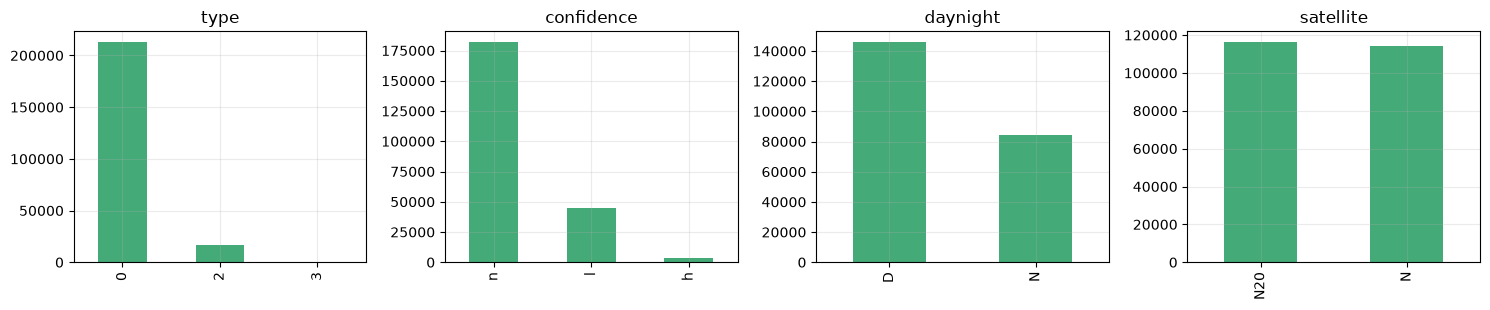

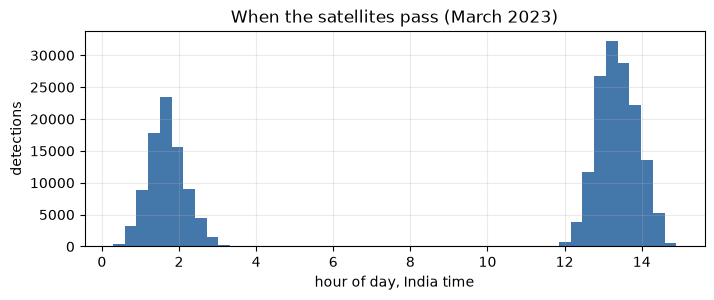

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, col in zip(ax, ["type", "confidence", "daynight", "satellite"]):
    raw[col].value_counts().plot.bar(ax=a, color="#4a7"); a.set_title(col); a.set_xlabel("")
plt.tight_layout(); plt.show()

hours = (raw.acq_time // 100 + raw.acq_time % 100 / 60 + 5.5) % 24         # UTC to India time
plt.figure(figsize=(8, 2.8)); plt.hist(hours, bins=48, color="#47a"); plt.xlabel("hour of day, India time"); plt.ylabel("detections"); plt.title("When the satellites pass (March 2023)"); plt.show()

The satellites do not film the forest all day. They pass a few times a day, so one **cell-day** gets only a few snapshots.
No detection does not mean no fire; it can mean "no pass saw it" (cloud, smoke, a small cool fire).

## 2. What we throw away (cleaning)

In [4]:
n0 = len(raw)
keep = raw[raw.type == 0]
print(f"start                        {n0:8d}")
print(f"- not a vegetation fire      {n0 - len(keep):8d}   (type 2 and 3)")
k2 = keep[keep.confidence.isin(["n", "h"])]
print(f"- low confidence             {len(keep) - len(k2):8d}   (confidence 'l')")
k3 = k2.drop_duplicates()
print(f"- exact duplicates           {len(k2) - len(k3):8d}")
print(f"left                         {len(k3):8d}   ({100 * len(k3) / n0:.0f}% of the raw rows)")

start                          230275
- not a vegetation fire         17614   (type 2 and 3)
- low confidence                44200   (confidence 'l')
- exact duplicates                  0
left                           168461   (73% of the raw rows)


Rules we follow: `type == 0`, `confidence` is `n` or `h`, no exact duplicates. The same rule is used for all states and all years.

## 3. What is left: all cleaned detections, 2019 to 2025

In [5]:
d = pd.concat([pd.read_parquet(f"{DS}/detections_forest.parquet"), pd.read_parquet(f"{DS}/detections_new.parquet")], ignore_index=True)
print(len(d), "cleaned detections;", d.date_utc.min().date(), "to", d.date_utc.max().date())
print("by satellite:", d.satellite.value_counts().to_dict(), "  by confidence:", d.confidence.value_counts().to_dict())
display(d.head(4))

3553946 cleaned detections; 2019-01-01 to 2026-01-03
by satellite: {'N20': 1785039, 'N': 1768907}   by confidence: {'n': 3421815, 'h': 132131}


,latitude,longitude,satellite,confidence,date_utc,cell_id,set,bnd333,bnd777,state
0,18.97511,82.00784,N20,n,2019-01-01,190820,six,0.0,0.163265,NaN
1,19.62579,82.48304,N20,n,2019-01-01,196825,six,0.0,0.000000,NaN
2,19.62656,82.48329,N20,n,2019-01-01,196825,six,0.0,0.000000,NaN
3,19.63218,82.48109,N20,n,2019-01-01,196825,six,0.0,0.000000,NaN


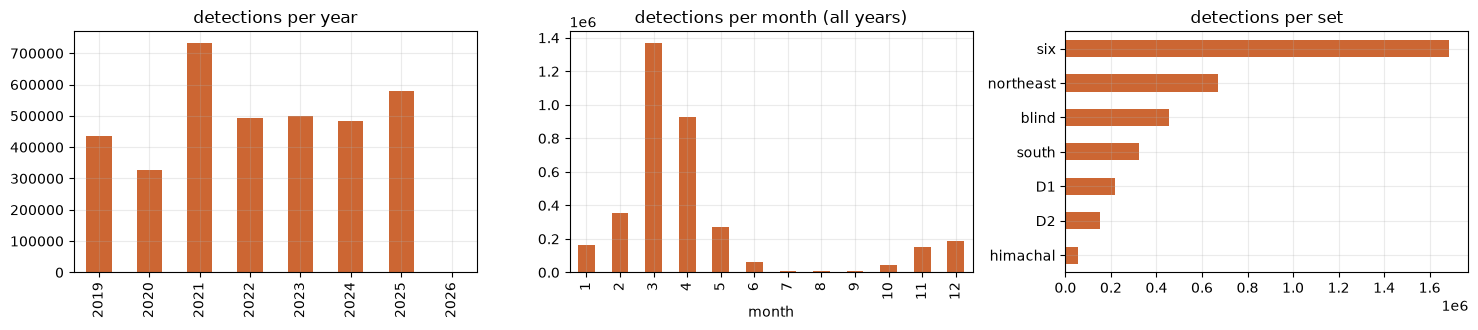

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
d.groupby(d.date_utc.dt.year).size().plot.bar(ax=ax[0], color="#c63"); ax[0].set_title("detections per year"); ax[0].set_xlabel("")
d.groupby(d.date_utc.dt.month).size().plot.bar(ax=ax[1], color="#c63"); ax[1].set_title("detections per month (all years)"); ax[1].set_xlabel("month")
d.groupby("set").size().sort_values().plot.barh(ax=ax[2], color="#c63"); ax[2].set_title("detections per set"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

Fires are **seasonal**: almost all of them are in February to May (peak March). The monsoon months have almost none.
This is why only about 2.6 out of 100 rows (cell-days) are fire days overall. (In the January to May sample we used for quick tests it is about 6 out of 100, because that sample leaves out the quiet months.)

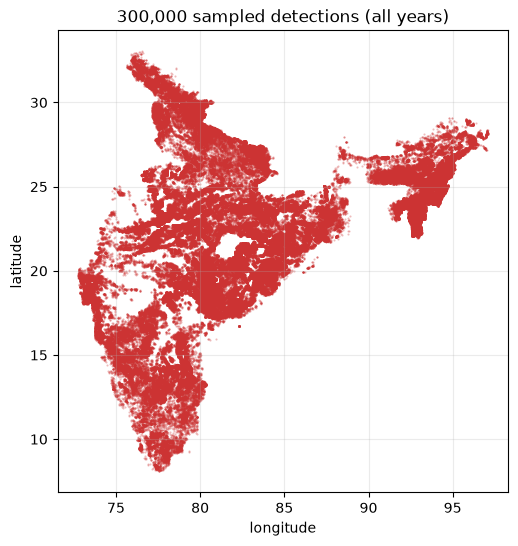

In [7]:
s = d.sample(300000, random_state=0)
plt.figure(figsize=(6, 6)); plt.scatter(s.longitude, s.latitude, s=0.3, alpha=0.3, color="#c33"); plt.gca().set_aspect("equal")
plt.title("300,000 sampled detections (all years)"); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.show()

## 4. From a point to a cell-day

In [8]:
# A detection belongs to the 0.1 degree cell whose centre is nearest.  cell_id = lat_index * 1000 + lon_index, index = round(coord * 10)
calc = np.round(d.latitude * 10).astype(int) * 1000 + np.round(d.longitude * 10).astype(int)
print("cell_id recomputed from the coordinates matches the stored cell_id for", round(100 * (calc == d.cell_id).mean(), 2), "% of detections")
one = d.iloc[0]; print("example:", one.latitude, one.longitude, "-> cell", int(one.cell_id))

cell_id recomputed from the coordinates matches the stored cell_id for 100.0 % of detections
example: 18.97511 82.00784 -> cell 190820


## 5. Is the fire inside the forest?

A 375 m pixel can lie half in forest, half in a field. For each detection we measure how much of its footprint lies **inside the forest boundary**
(`bnd333`: 3 x 3 small pixels, about 330 m, `bnd777`: about 770 m). If at least half is inside, it counts as a **forest fire**.

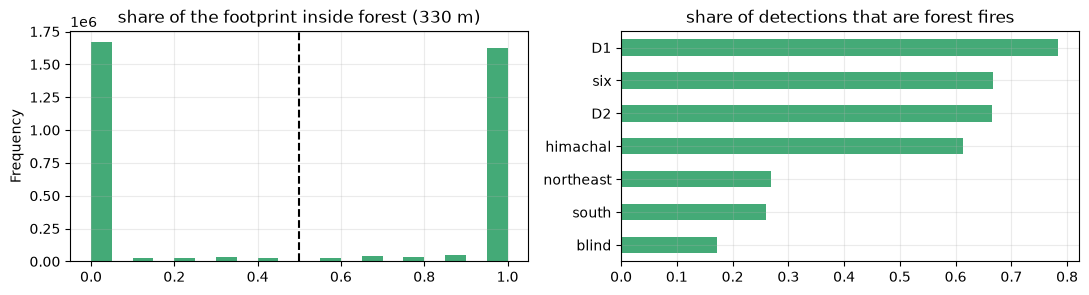

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
d.bnd333.plot.hist(bins=20, ax=ax[0], color="#4a7"); ax[0].set_title("share of the footprint inside forest (330 m)"); ax[0].axvline(0.5, color="k", ls="--")
(d.groupby("set").apply(lambda g: (g.bnd333 >= 0.5).mean())).sort_values().plot.barh(ax=ax[1], color="#4a7"); ax[1].set_title("share of detections that are forest fires"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

Detections that lie in a forest cell but whose footprint is not in the boundary (fields, plantations, burning of crop waste) are marked **ambiguous**
and removed from training and scoring. Notebook 06 shows how many.

## 6. What is missing or weak here

- **Cloud and smoke** hide fires. A fire under cloud gives no detection, so some negative rows are really fires.
- **Small or cool fires** under a 375 m pixel are not seen. Ground fires under a thick canopy are partly hidden.
- **Only a few passes a day.** A short fire between two passes is missed.
- **We only get detections, not burned area.** A fire that lasts a week is seven separate yes-rows.
- **Not all fires are forest fires.** Crop burning near forest edges is a real source of ambiguity (see section 5).
- The live demo needs the same data in near real time. FIRMS offers that, with a few hours delay.